# Assignment 6 - Language Identification

**Name:** Tanu Meena  
**Roll number:** U23AI076

This notebook follows `assign1&assign2.ipynb` for the 23 IndicCorpV2 labels,
paragraph-to-sentence tokenization, and 80:10:10 split. That notebook actually
collected **2,000 sentences per language**, giving 1,600 training, 200 validation,
and 200 test sentences per class. We keep those counts for this comparison.
Assignment 2 supplies the custom logistic-regression idea; Assignment 5 supplies
the average-word-vector representation.

The seven classifiers are logistic regression, MLP with 0/1/2 hidden layers,
LSTM, GRU, and supervised FastText. All evaluation code is implemented below
using NumPy. No sklearn classes or metrics are used.

References: [IndicCorpV2](https://huggingface.co/datasets/ai4bharat/IndicCorpV2),
[FastText Wiki vectors](https://fasttext.cc/docs/en/pretrained-vectors.html), and
[FastText supervised tutorial](https://fasttext.cc/docs/en/supervised-tutorial.html).

## 1. Setup

Run the cells in order from the assignment folder. The first run downloads corpus
prefixes and reads the complete required Wiki vector files from the official
compressed archives. Only vectors needed by this experiment are cached locally.
Later runs reuse data, vectors, and models.

Install `requirements-assignment6.txt` in a Python 3.12 environment on Windows.
On the current Python 3.14 installation, the FastText section can also use the
local Python 3.12 helper in `assignment6_artifacts/runtime/fasttext_python`.

In [1]:
import copy
import gc
import hashlib
import io
import json
import math
import os
import random
import re
import subprocess
import struct
import sys
import time
import unicodedata
import zipfile
import zlib
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from IPython.display import display
from requests.adapters import HTTPAdapter
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset, TensorDataset
from urllib3.util.retry import Retry

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

OUTPUT_DIR = Path("assignment6_artifacts")
DATA_DIR = OUTPUT_DIR / "data"
VECTOR_DIR = OUTPUT_DIR / "wiki_vectors"
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"
for directory in (DATA_DIR, VECTOR_DIR, MODEL_DIR, PLOT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

LANGUAGES = [
    "asm_Beng", "ben_Beng", "brx_Deva", "doi_Deva", "gom_Deva",
    "guj_Gujr", "hin_Deva", "kan_Knda", "kas_Arab", "mai_Deva",
    "mal_Mlym", "mar_Deva", "mni_Mtei", "npi_Deva", "ory_Orya",
    "pan_Guru", "san_Deva", "snd_Deva", "tam_Taml", "tel_Telu",
    "urd_Arab", "khasi", "santhali",
]
NUM_CLASSES = len(LANGUAGES)
LABEL_TO_ID = {label: i for i, label in enumerate(LANGUAGES)}
SENTENCES_PER_LANGUAGE = 2_000
TRAIN_PER_LANGUAGE = 1_600
VAL_PER_LANGUAGE = TEST_PER_LANGUAGE = 200
REPO_ID = "ai4bharat/IndicCorpV2"
CORPUS_REVISION = "2d7285e6ce14fdb3fb2449c9f89427b9f582ac3f"
CORPUS_FILES = dict(zip(LANGUAGES, [
    "as.txt", "bn.txt", "bd.txt", "dg.txt", "gom.txt", "gu.txt",
    "hi-1.txt", "kn.txt", "ks.txt", "mai.txt", "ml.txt", "mr.txt",
    "mni.txt", "ne.txt", "or.txt", "pa.txt", "sa.txt", "sd.txt",
    "ta.txt", "te.txt", "ur.txt", "kha.txt", "sat.txt",
]))

VECTOR_SIZE = 300
WIKI_CODES = dict(zip(LANGUAGES, [
    "as", "bn", None, None, "gom", "gu", "hi", "kn", "ks", "mai",
    "ml", "mr", None, "ne", "or", "pa", "sa", "sd", "ta", "te",
    "ur", None, None,
]))
LR_EPOCHS = 50
LR_RATE = 0.5
DENSE_EPOCHS = 20
RNN_EPOCHS = 15
NEURAL_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 4
DENSE_BATCH_SIZE = 256
RNN_BATCH_SIZE = 128
MAX_SEQ_LEN = 96
RNN_HIDDEN_SIZE = 64
DROPOUT = 0.2
FASTTEXT_EPOCHS = 25
FASTTEXT_RATE = 0.5
FASTTEXT_BUCKET = 100_000
FORCE_RETRAIN = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

http = requests.Session()
http.mount("https://", HTTPAdapter(max_retries=Retry(
    total=4, backoff_factor=0.5, status_forcelist=[429, 500, 502, 503, 504]
)))

def stable_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True,
                                    ensure_ascii=False).encode("utf-8")).hexdigest()

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2),
                          encoding="utf-8")

print("Device:", DEVICE)
print("Classes:", NUM_CLASSES)
print("Output folder:", OUTPUT_DIR.resolve())

Device: cpu
Classes: 23
Output folder: C:\Users\Tanu Meena\OneDrive\Desktop\llm\lab6\assignment6_artifacts


## 2. Reuse or reconstruct Assignment 1's dataset

If Assignment 1's six data/label variables are already present in this kernel,
their exact values are saved and reused. Otherwise, cached JSONL splits are used.
If neither exists, the dataset is reconstructed using Assignment 1's tokenizer,
first-2,000-sentence sampling, and contiguous per-language split, from a pinned
IndicCorpV2 revision. The old notebook did not save its sentence lists, so exact
equality with its previous in-memory data cannot be certified after that kernel
has closed. The reconstruction procedure and source revision are recorded.

HTTP byte ranges read only the beginning of each large corpus file. Paragraph
boundaries are preserved across requests. No language is silently skipped.

In [2]:
def extract_sentences(paragraph):
    # Identical sentence boundaries and minimum length to Assignment 1.
    pieces = re.split(r"[.!?।\|]+", paragraph)
    return [piece.strip() for piece in pieces if len(piece.strip().split()) >= 3]

def collect_assignment1_sentences(language):
    url = (f"https://huggingface.co/datasets/{REPO_ID}/resolve/"
           f"{CORPUS_REVISION}/data/{CORPUS_FILES[language]}")
    collected, offset, pending = [], 0, b""
    chunk_bytes = 512 * 1024
    while len(collected) < SENTENCES_PER_LANGUAGE:
        response = http.get(url, headers={
            "Range": f"bytes={offset}-{offset + chunk_bytes - 1}"
        }, stream=True, timeout=(20, 120))
        response.raise_for_status()
        try:
            if response.status_code != 206:
                raise RuntimeError(f"Byte-range support required for {language}.")
            start, end, total = map(int, re.fullmatch(
                r"bytes (\d+)-(\d+)/(\d+)",
                response.headers["Content-Range"]
            ).groups())
            if start != offset:
                raise RuntimeError(f"Incorrect byte range returned for {language}.")
            block = response.content
        finally:
            response.close()
        lines = (pending + block).split(b"\n")
        pending = lines.pop()
        if end + 1 == total and pending:
            lines.append(pending)
            pending = b""
        for line in lines:
            if line.strip():
                collected.extend(extract_sentences(line.decode("utf-8")))
            if len(collected) >= SENTENCES_PER_LANGUAGE:
                return collected[:SENTENCES_PER_LANGUAGE]
        offset = end + 1
        if offset >= total:
            raise RuntimeError(
                f"{language} provides {len(collected)} usable sentences; "
                f"{SENTENCES_PER_LANGUAGE} are required."
            )
    return collected[:SENTENCES_PER_LANGUAGE]

def save_split(path, texts, labels):
    with path.open("w", encoding="utf-8") as handle:
        for text, label in zip(texts, labels):
            handle.write(json.dumps({"text": text, "label": LANGUAGES[int(label)]},
                                    ensure_ascii=False) + "\n")

def read_split(path):
    records = [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines()
               if line.strip()]
    return ([row["text"] for row in records],
            np.asarray([LABEL_TO_ID[row["label"]] for row in records], dtype=np.int64))

def validate_splits(texts, labels):
    counts = [TRAIN_PER_LANGUAGE, VAL_PER_LANGUAGE, TEST_PER_LANGUAGE]
    for name, documents, ids, expected in zip(
            ["train", "validation", "test"], texts, labels, counts):
        if len(documents) != len(ids) or len(documents) != expected * NUM_CLASSES:
            raise ValueError(f"Unexpected size for {name}; expected {expected} per class.")
        if np.any((np.asarray(ids) < 0) | (np.asarray(ids) >= NUM_CLASSES)):
            raise ValueError(f"Invalid labels in {name}.")
        if not np.all(np.bincount(ids, minlength=NUM_CLASSES) == expected):
            raise ValueError(f"{name} is not balanced across all 23 languages.")
        if any(not isinstance(text, str) or len(text.split()) < 3 for text in documents):
            raise ValueError(f"Invalid sentence in {name}.")

def load_assignment1_data(namespace):
    names = ["train_data", "val_data", "test_data",
             "train_labels", "val_labels", "test_labels"]
    paths = [DATA_DIR / f"{split}.jsonl" for split in ["train", "validation", "test"]]
    if all(name in namespace for name in names):
        if "languages" in namespace and list(namespace["languages"]) != LANGUAGES:
            raise ValueError("Assignment 1's label ordering differs from LANGUAGES.")
        texts = [list(namespace[name]) for name in names[:3]]
        labels = [np.asarray(namespace[name], dtype=np.int64) for name in names[3:]]
        validate_splits(texts, labels)
        source = "Exact sentence lists reused from the live Assignment 1 kernel."
    elif all(path.exists() for path in paths):
        loaded = [read_split(path) for path in paths]
        texts, labels = [row[0] for row in loaded], [row[1] for row in loaded]
        validate_splits(texts, labels)
        manifest_path = DATA_DIR / "manifest.json"
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        if manifest["languages"] != LANGUAGES or manifest["sentences_per_language"] != SENTENCES_PER_LANGUAGE:
            raise ValueError("The cached dataset has a different experiment configuration.")
        if any(file_hash(path) != manifest["split_sha256"][path.stem] for path in paths):
            raise ValueError("Cached split contents differ from the saved dataset manifest.")
        return texts, labels, manifest
    else:
        texts, labels = [[], [], []], [[], [], []]
        for label_id, language in enumerate(LANGUAGES):
            sentences = collect_assignment1_sentences(language)
            boundaries = [(0, TRAIN_PER_LANGUAGE),
                          (TRAIN_PER_LANGUAGE, TRAIN_PER_LANGUAGE + VAL_PER_LANGUAGE),
                          (TRAIN_PER_LANGUAGE + VAL_PER_LANGUAGE, SENTENCES_PER_LANGUAGE)]
            for split_id, (start, stop) in enumerate(boundaries):
                texts[split_id].extend(sentences[start:stop])
                labels[split_id].extend([label_id] * (stop - start))
            print(f"{language:10}: 1,600 / 200 / 200", flush=True)
        labels = [np.asarray(ids, dtype=np.int64) for ids in labels]
        validate_splits(texts, labels)
        source = "Reconstructed with Assignment 1's sampling and split procedure."
    for path, documents, ids in zip(paths, texts, labels):
        save_split(path, documents, ids)
    manifest = {
        "source": source, "repository": REPO_ID, "revision": CORPUS_REVISION,
        "languages": LANGUAGES, "sentences_per_language": SENTENCES_PER_LANGUAGE,
        "split_per_language": [TRAIN_PER_LANGUAGE, VAL_PER_LANGUAGE, TEST_PER_LANGUAGE],
        "split_sha256": {path.stem: file_hash(path) for path in paths},
        "sentence_tokenizer": r"[.!?।\|]+; retain sentences with at least three words",
    }
    write_json(DATA_DIR / "manifest.json", manifest)
    return texts, labels, manifest

In [3]:
split_texts, split_labels, data_manifest = load_assignment1_data(globals())
train_data, val_data, test_data = split_texts
train_labels, val_labels, test_labels = split_labels
print(data_manifest["source"])

split_summary = pd.DataFrame({
    "language": LANGUAGES,
    "train": np.bincount(train_labels, minlength=NUM_CLASSES),
    "validation": np.bincount(val_labels, minlength=NUM_CLASSES),
    "test": np.bincount(test_labels, minlength=NUM_CLASSES),
})
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
display(split_summary)
print("Total sentences:", len(train_data), len(val_data), len(test_data))

duplicate_rows = []
for label_id, language in enumerate(LANGUAGES):
    training = {text for text, label in zip(train_data, train_labels) if label == label_id}
    validation = [text for text, label in zip(val_data, val_labels) if label == label_id]
    testing = [text for text, label in zip(test_data, test_labels) if label == label_id]
    duplicate_rows.append({
        "language": language, "unique_train_sentences": len(training),
        "validation_sentences_also_in_train": sum(text in training for text in validation),
        "test_sentences_also_in_train": sum(text in training for text in testing),
    })
duplicate_audit = pd.DataFrame(duplicate_rows)
duplicate_audit.to_csv(OUTPUT_DIR / "duplicate_audit.csv", index=False)
print("Exact train/validation overlaps:",
      int(duplicate_audit["validation_sentences_also_in_train"].sum()))
print("Exact train/test overlaps:",
      int(duplicate_audit["test_sentences_also_in_train"].sum()))

Reconstructed with Assignment 1's sampling and split procedure.


,language,train,validation,test
0,asm_Beng,1600,200,200
1,ben_Beng,1600,200,200
2,brx_Deva,1600,200,200
3,doi_Deva,1600,200,200
4,gom_Deva,1600,200,200
5,guj_Gujr,1600,200,200
6,hin_Deva,1600,200,200
7,kan_Knda,1600,200,200
8,kas_Arab,1600,200,200
9,mai_Deva,1600,200,200


Total sentences: 36800 4600 4600
Exact train/validation overlaps: 155
Exact train/test overlaps: 110


## 3. Macro-F1 from scratch

For each class, precision is TP/(TP+FP), recall is TP/(TP+FN), and
F1 is 2TP/(2TP+FP+FN). Macro-F1 is the arithmetic mean of all **23** class F1
scores. A class with a zero denominator receives F1 = 0. Classes with missing
embeddings are still included in evaluation.

In [4]:
def custom_classification_metrics(y_true, y_pred, num_classes=NUM_CLASSES):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)
    if y_true.ndim != 1 or y_pred.shape != y_true.shape or not len(y_true):
        raise ValueError("Expected nonempty one-dimensional label arrays of equal size.")
    if np.any((y_true < 0) | (y_true >= num_classes)) or np.any((y_pred < 0) | (y_pred >= num_classes)):
        raise ValueError("Label IDs must lie in [0, num_classes).")
    confusion = np.zeros((num_classes, num_classes), dtype=np.int64)
    np.add.at(confusion, (y_true, y_pred), 1)
    tp = np.diag(confusion).astype(np.float64)
    support = confusion.sum(axis=1)
    predicted = confusion.sum(axis=0)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted != 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support != 0)
    f1 = np.divide(2 * tp, support + predicted, out=np.zeros_like(tp),
                   where=(support + predicted) != 0)
    return {
        "macro_f1": float(f1.mean()), "accuracy": float(tp.sum() / len(y_true)),
        "precision": precision, "recall": recall, "f1": f1,
        "support": support, "confusion": confusion,
    }

def macro_f1_score(y_true, y_pred, num_classes=NUM_CLASSES):
    return custom_classification_metrics(y_true, y_pred, num_classes)["macro_f1"]

# Hand-calculated non-perfect example: per-class F1 = 0.5, 0.8, 2/3.
assert np.isclose(macro_f1_score([0, 0, 1, 1, 2, 2], [0, 1, 1, 1, 0, 2], 3),
                  (0.5 + 0.8 + 2 / 3) / 3)
assert np.isclose(macro_f1_score([0, 0], [0, 0], 3), 1 / 3)
print("Custom macro-F1 checks passed.")

Custom macro-F1 checks passed.


## 4. FastText Wiki word vectors

The linked Wiki release supplies models for 18 of our 23 languages. It does not
supply Bodo (`brx_Deva`), Dogri (`doi_Deva`), Manipuri (`mni_Mtei`), Khasi, or
Santali. Their text is retained, and any words found in the other downloaded
models can still be represented. Words absent from every Wiki model use a zero
unknown vector; missing models are never replaced with invented pretrained
vectors. Coverage is measured separately for each language and split.

**Lookup never uses a sentence's true label.** We build one shared 300-dimensional
table from all 18 models. If a word appears in several models, its normalized
vectors are averaged and normalized again, using a fixed, label-independent
rule. These monolingual spaces are not aligned; this is a classification feature
construction, not a claim about cross-language semantic similarity.

Only a fixed pretrained lookup is filtered using the union of input words. No
labels, fitted statistics, or model parameters are obtained from held-out text.
Native supervised FastText is initialized with the merged **training-word**
vectors, and can learn character n-grams for uncovered words from training data.

The download reads the compressed `.vec` member of each official ZIP archive
using bounded parallel HTTP ranges. Cache writes stay ordered, and size, CRC,
and vocabulary-row-count checks verify complete extraction.

In [5]:
def word_tokens(text):
    return unicodedata.normalize("NFC", text).split()

all_words = sorted({word for documents in split_texts for text in documents
                    for word in word_tokens(text)})
WORD_TO_ID = {word: i + 2 for i, word in enumerate(all_words)}
write_json(OUTPUT_DIR / "vocabulary.json", WORD_TO_ID)
PAD_ID, UNK_ID = 0, 1
VOCAB_HASH = stable_hash(all_words)

def read_filtered_wiki_vectors(code, wanted_words):
    cache = VECTOR_DIR / f"wiki.{code}.npz"
    meta_file = VECTOR_DIR / f"wiki.{code}.json"
    if cache.exists() and meta_file.exists():
        metadata = json.loads(meta_file.read_text(encoding="utf-8"))
        if metadata.get("vocabulary_sha256") == VOCAB_HASH and metadata["complete"]:
            with np.load(cache, allow_pickle=False) as saved:
                vectors = dict(zip(saved["words"].tolist(), saved["vectors"]))
            print(f"wiki.{code}: cached, {len(vectors):,} matching words", flush=True)
            return vectors, metadata

    # Official ZIPs contain the same .vec text plus a much larger .bin model.
    # Read the ZIP directory and fetch only the compressed .vec member.
    archive_url = f"https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{code}.zip"
    archive_meta_path = VECTOR_DIR / f"wiki.{code}.archive.json"
    if archive_meta_path.exists():
        archive = json.loads(archive_meta_path.read_text(encoding="utf-8"))
    else:
        response = http.get(archive_url, headers={"Range": "bytes=-65536"},
                            stream=True, timeout=(20, 120))
        response.raise_for_status()
        try:
            if response.status_code != 206:
                raise RuntimeError(f"Wiki ZIP byte ranges are unavailable: {code}.")
            archive_bytes = int(response.headers["Content-Range"].split("/")[-1])
            tail = response.content
        finally:
            response.close()
        with zipfile.ZipFile(io.BytesIO(tail)) as directory:
            member = next(info for info in directory.infolist()
                          if Path(info.filename).name == f"wiki.{code}.vec")
            # ZipFile offsets are relative to the downloaded tail buffer.
            local_offset = member.header_offset + archive_bytes - len(tail)
            archive = {
                "url": archive_url, "member": member.filename,
                "archive_bytes": archive_bytes, "local_offset": local_offset,
                "compressed_bytes": member.compress_size, "raw_bytes": member.file_size,
                "crc32": member.CRC, "compression": member.compress_type,
            }
        response = http.get(archive_url, headers={
            "Range": f"bytes={local_offset}-{local_offset + 29}"
        }, stream=True, timeout=(20, 120))
        response.raise_for_status()
        try:
            if response.status_code != 206:
                raise RuntimeError(f"Wiki ZIP local header unavailable: {code}.")
            header = struct.unpack("<4s5H3I2H", response.content)
        finally:
            response.close()
        if header[0] != b"PK\x03\x04" or header[2] & 1:
            raise ValueError(f"Invalid/encrypted Wiki ZIP member: {code}.")
        archive["data_offset"] = local_offset + 30 + header[-2] + header[-1]
        write_json(archive_meta_path, archive)

    compressed_path = VECTOR_DIR / f"wiki.{code}.vec.deflate.part"
    completed_bytes = compressed_path.stat().st_size if compressed_path.exists() else 0
    if completed_bytes > archive["compressed_bytes"]:
        raise ValueError(f"Oversized compressed Wiki cache: {code}.")
    chunk_bytes = 16 * 1024 * 1024

    def fetch_range(relative_offset):
        start = archive["data_offset"] + relative_offset
        length = min(chunk_bytes, archive["compressed_bytes"] - relative_offset)
        # These concurrent operations only read the remote file. Local cache
        # writes below remain ordered in the calling thread.
        with requests.Session() as session:
            session.mount("https://", HTTPAdapter(max_retries=Retry(
                total=4, backoff_factor=0.5, status_forcelist=[429, 500, 502, 503, 504])))
            response = session.get(archive_url, headers={
                "Range": f"bytes={start}-{start + length - 1}"
            }, stream=True, timeout=(20, 180))
            response.raise_for_status()
            try:
                if response.status_code != 206:
                    raise RuntimeError(f"Wiki ZIP vector range unavailable: {code}.")
                actual_start = int(response.headers["Content-Range"].split()[1].split("-")[0])
                block = response.content
                if actual_start != start or len(block) != length:
                    raise RuntimeError(f"Incomplete Wiki ZIP vector range: {code}.")
                return block
            finally:
                response.close()

    offsets = iter(range(completed_bytes, archive["compressed_bytes"], chunk_bytes))
    with ThreadPoolExecutor(max_workers=4) as pool, compressed_path.open("ab") as handle:
        pending_requests = {}

        def schedule_next():
            offset = next(offsets, None)
            if offset is not None:
                pending_requests[offset] = pool.submit(fetch_range, offset)

        for _ in range(4):
            schedule_next()
        while pending_requests:
            offset = min(pending_requests)
            block = pending_requests.pop(offset).result()
            handle.write(block)
            handle.flush()
            completed_bytes += len(block)
            print(f"wiki.{code}: compressed vectors {completed_bytes / 2**20:.1f}/"
                  f"{archive['compressed_bytes'] / 2**20:.1f} MiB", flush=True)
            schedule_next()

    vectors, pending_line = {}, b""
    scanned, declared_rows, raw_bytes, crc = 0, None, 0, 0
    decompressor = zlib.decompressobj(-15) if archive["compression"] == zipfile.ZIP_DEFLATED else None
    if decompressor is None and archive["compression"] != zipfile.ZIP_STORED:
        raise ValueError(f"Unsupported Wiki ZIP compression: {code}.")

    def consume(raw):
        nonlocal pending_line, scanned, declared_rows, raw_bytes, crc
        raw_bytes += len(raw)
        crc = zlib.crc32(raw, crc)
        lines = (pending_line + raw).split(b"\n")
        pending_line = lines.pop()
        for line in lines:
            if declared_rows is None:
                rows, dimension = map(int, line.split())
                if dimension != VECTOR_SIZE:
                    raise ValueError(f"Wrong Wiki vector dimension: {code}.")
                declared_rows = rows
                continue
            word_bytes, separator, vector_bytes = line.partition(b" ")
            if not separator:
                continue
            scanned += 1
            word = word_bytes.decode("utf-8", errors="replace")
            if word in wanted_words:
                vector = np.fromstring(vector_bytes.decode("ascii"), sep=" ", dtype=np.float32)
                if vector.size != VECTOR_SIZE or not np.isfinite(vector).all():
                    raise ValueError(f"Invalid Wiki vector for {word!r} in {code}.")
                vectors[word] = vector / max(float(np.linalg.norm(vector)), 1e-12)

    with compressed_path.open("rb") as handle:
        for block in iter(lambda: handle.read(256 * 1024), b""):
            consume(decompressor.decompress(block) if decompressor else block)
    if decompressor:
        consume(decompressor.flush())
        if not decompressor.eof:
            raise ValueError(f"Truncated Wiki ZIP vector member: {code}.")
    if pending_line:
        # A final vector row is valid even without a trailing newline.
        final_line = pending_line
        pending_line = b""
        before_bytes, before_crc = raw_bytes, crc
        consume(final_line + b"\n")
        raw_bytes, crc = before_bytes, before_crc
    if raw_bytes != archive["raw_bytes"] or crc != archive["crc32"] or scanned != declared_rows:
        raise ValueError(f"Wiki vector size/CRC/row-count check failed: {code}.")
    items = sorted(vectors)
    matrix = np.stack([vectors[word] for word in items]) if items else np.empty((0, VECTOR_SIZE), dtype=np.float32)
    temporary = cache.with_name(cache.stem + ".pending.npz")
    np.savez_compressed(temporary, words=np.asarray(items, dtype=str), vectors=matrix)
    os.replace(temporary, cache)
    metadata = {
        "code": code, "url": f"https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{code}.vec",
        "dimension": VECTOR_SIZE, "vocabulary_sha256": VOCAB_HASH,
        "cursor": raw_bytes, "scanned_rows": scanned, "declared_rows": declared_rows,
        "total_bytes": raw_bytes, "matching_words": len(items), "complete": True,
        "archive_url": archive_url, "archive_member": archive["member"],
        "archive_crc32": crc, "compressed_bytes": archive["compressed_bytes"],
    }
    write_json(meta_file, metadata)
    compressed_path.unlink()
    print(f"wiki.{code}: verified {scanned:,} rows; {len(vectors):,} matching words", flush=True)
    return vectors, metadata

def build_shared_embeddings():
    merged_path = VECTOR_DIR / "shared_embeddings.npz"
    manifest_path = VECTOR_DIR / "embedding_manifest.json"
    codes = sorted({code for code in WIKI_CODES.values() if code})
    lookup_rule = "mean_of_unit_wiki_vectors_then_l2_normalize_v1"
    if merged_path.exists() and manifest_path.exists():
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        if (manifest.get("vocabulary_sha256") == VOCAB_HASH
                and manifest.get("wiki_codes") == codes
                and manifest.get("lookup_rule") == lookup_rule):
            with np.load(merged_path, allow_pickle=False) as saved:
                matrix, counts = saved["vectors"], saved["source_counts"]
            print("Using cached shared Wiki embeddings.")
            return matrix, counts, manifest
    page = http.get("https://fasttext.cc/docs/en/pretrained-vectors.html", timeout=(20, 60))
    page.raise_for_status()
    available = set(re.findall(r"wiki\.([a-z_-]+)\.vec", page.text))
    if not set(codes) <= available:
        raise RuntimeError(f"Wiki models missing from the official page: {set(codes) - available}")
    matrix = np.zeros((len(all_words) + 2, VECTOR_SIZE), dtype=np.float32)
    counts = np.zeros(len(all_words) + 2, dtype=np.int16)
    sources = []
    for code in codes:
        vectors, metadata = read_filtered_wiki_vectors(code, set(all_words))
        for word, vector in vectors.items():
            index = WORD_TO_ID[word]
            matrix[index] += vector
            counts[index] += 1
        sources.append(metadata)
        del vectors
        gc.collect()
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    matrix /= np.maximum(norms, 1e-12)
    matrix[PAD_ID] = matrix[UNK_ID] = 0
    np.savez_compressed(merged_path, vectors=matrix, source_counts=counts)
    manifest = {
        "dimension": VECTOR_SIZE, "vocabulary_sha256": VOCAB_HASH,
        "wiki_codes": codes, "lookup_rule": lookup_rule,
        "missing_wiki_languages": [label for label in LANGUAGES if WIKI_CODES[label] is None],
        "sources": sources, "shared_embeddings_sha256": file_hash(merged_path),
        "gold_labels_used_for_lookup": False,
    }
    write_json(manifest_path, manifest)
    return matrix, counts, manifest

In [6]:
embedding_matrix, embedding_source_counts, embedding_manifest = build_shared_embeddings()
print("Shared embedding shape:", embedding_matrix.shape)
print("Words covered:", int((embedding_source_counts > 0).sum()), "/", len(all_words))
print("Languages without their own Wiki model:", embedding_manifest["missing_wiki_languages"])

coverage_rows = []
for split, documents, labels in zip(["train", "validation", "test"], split_texts, split_labels):
    for label_id, language in enumerate(LANGUAGES):
        total = covered = zero_sentences = sentence_count = truncated = 0
        for sentence, label in zip(documents, labels):
            if label != label_id:
                continue
            ids = [WORD_TO_ID.get(word, UNK_ID) for word in word_tokens(sentence)]
            matches = sum(embedding_source_counts[index] > 0 for index in ids)
            total += len(ids)
            covered += matches
            zero_sentences += int(matches == 0)
            sentence_count += 1
            truncated += int(len(ids) > MAX_SEQ_LEN)
        coverage_rows.append({
            "split": split, "language": language, "wiki_code": WIKI_CODES[language],
            "word_tokens": total, "covered_tokens": covered,
            "coverage": covered / max(total, 1),
            "sentences": sentence_count, "all_oov_sentences": zero_sentences,
            "rnn_truncated_sentences": truncated,
        })
coverage_df = pd.DataFrame(coverage_rows)
coverage_df.to_csv(OUTPUT_DIR / "embedding_coverage.csv", index=False)
display(coverage_df[coverage_df["split"] == "test"].reset_index(drop=True))

Using cached shared Wiki embeddings.
Shared embedding shape: (221033, 300)
Words covered: 105318 / 221031
Languages without their own Wiki model: ['brx_Deva', 'doi_Deva', 'mni_Mtei', 'khasi', 'santhali']


,split,language,wiki_code,word_tokens,covered_tokens,coverage,sentences,all_oov_sentences,rnn_truncated_sentences
0,test,asm_Beng,as,3113,2520,0.809509,200,2,1
1,test,ben_Beng,bn,2407,2135,0.886996,200,0,0
2,test,brx_Deva,NaN,3375,1111,0.329185,200,24,0
3,test,doi_Deva,NaN,2362,1456,0.616427,200,5,0
4,test,gom_Deva,gom,2028,1622,0.799803,200,0,0
5,test,guj_Gujr,gu,2793,2382,0.852846,200,0,0
6,test,hin_Deva,hi,3374,3114,0.922940,200,0,0
7,test,kan_Knda,kn,2097,1621,0.773009,200,0,0
8,test,kas_Arab,ks,4117,1211,0.294146,200,5,3
9,test,mai_Deva,mai,2828,2001,0.707567,200,2,2


## 5. Sentence features and padded sequences

Logistic regression and the MLPs receive the normalized mean of available Wiki
word vectors. An entirely uncovered sentence has a zero feature vector. LSTM
and GRU receive the word-vector sequence, with frozen pretrained embeddings,
a maximum of 96 words, and packed lengths so padding is never treated as text.
Truncation counts are included in the coverage table.

In [7]:
def averaged_sentence_vectors(documents):
    features = np.zeros((len(documents), VECTOR_SIZE), dtype=np.float32)
    for row, sentence in enumerate(documents):
        ids = [WORD_TO_ID.get(word, UNK_ID) for word in word_tokens(sentence)]
        known = [index for index in ids if embedding_source_counts[index] > 0]
        if known:
            features[row] = embedding_matrix[known].mean(axis=0)
    features /= np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-12)
    return features

X_train, X_val, X_test = [averaged_sentence_vectors(documents) for documents in split_texts]

class SequenceDataset(Dataset):
    def __init__(self, documents, labels):
        self.sequences = [torch.tensor(
            [WORD_TO_ID.get(word, UNK_ID) for word in word_tokens(sentence)[:MAX_SEQ_LEN]] or [UNK_ID],
            dtype=torch.long) for sentence in documents]
        self.labels = torch.as_tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]

def collate_sequences(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_ID)
    return padded, lengths, torch.stack(labels)

def dense_loaders():
    generator = torch.Generator().manual_seed(SEED)
    datasets = [TensorDataset(torch.from_numpy(features), torch.as_tensor(labels, dtype=torch.long))
                for features, labels in zip([X_train, X_val, X_test], split_labels)]
    return [DataLoader(dataset, batch_size=DENSE_BATCH_SIZE, shuffle=(i == 0),
                       generator=generator if i == 0 else None, num_workers=0)
            for i, dataset in enumerate(datasets)]

def sequence_loaders():
    generator = torch.Generator().manual_seed(SEED)
    datasets = [SequenceDataset(documents, labels) for documents, labels in zip(split_texts, split_labels)]
    return [DataLoader(dataset, batch_size=RNN_BATCH_SIZE, shuffle=(i == 0),
                       generator=generator if i == 0 else None,
                       collate_fn=collate_sequences, num_workers=0)
            for i, dataset in enumerate(datasets)]

experiment_config = {
    "seed": SEED, "languages": LANGUAGES,
    "dataset_sha256": data_manifest["split_sha256"],
    "embeddings_sha256": embedding_manifest["shared_embeddings_sha256"],
    "lr_epochs": LR_EPOCHS, "lr_rate": LR_RATE,
    "dense_epochs": DENSE_EPOCHS, "rnn_epochs": RNN_EPOCHS,
    "neural_rate": NEURAL_RATE, "weight_decay": WEIGHT_DECAY,
    "patience": PATIENCE, "dense_batch_size": DENSE_BATCH_SIZE,
    "rnn_batch_size": RNN_BATCH_SIZE, "max_sequence_length": MAX_SEQ_LEN,
    "rnn_hidden_size": RNN_HIDDEN_SIZE, "dropout": DROPOUT,
    "fasttext_epochs": FASTTEXT_EPOCHS, "fasttext_rate": FASTTEXT_RATE,
    "fasttext_bucket": FASTTEXT_BUCKET,
    "model_version": "lab6_v1",
}
RUN_SIGNATURE = stable_hash(experiment_config)
write_json(OUTPUT_DIR / "experiment_config.json", experiment_config)
write_json(OUTPUT_DIR / "labels.json", LABEL_TO_ID)
print("Averaged feature shapes:", X_train.shape, X_val.shape, X_test.shape)

Averaged feature shapes: (36800, 300) (4600, 300) (4600, 300)


## 6. Logistic regression from scratch

This is multinomial logistic regression: softmax(Wx + b), trained with
mini-batch cross-entropy gradients and L2 regularization. The learning rate
decays by 0.95 per epoch, following Assignment 1. The checkpoint is chosen by
validation macro-F1. Test labels are used only to compute the final metrics.

In [8]:
result_rows, histories, saved_predictions = [], {}, {}

def model_slug(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")

def register_result(name, validation_predictions, test_predictions, seconds, best_epoch, notes):
    validation_predictions = np.asarray(validation_predictions, dtype=np.int64)
    test_predictions = np.asarray(test_predictions, dtype=np.int64)
    validation = custom_classification_metrics(val_labels, validation_predictions)
    testing = custom_classification_metrics(test_labels, test_predictions)
    slug = model_slug(name)
    row = {
        "Model": name, "Validation_Macro_F1": validation["macro_f1"],
        "Test_Macro_F1": testing["macro_f1"],
        "Validation_Accuracy": validation["accuracy"], "Test_Accuracy": testing["accuracy"],
        "Best_Epoch": int(best_epoch), "Training_Seconds": float(seconds), "Notes": notes,
    }
    result_rows.append(row)
    saved_predictions[name] = {"validation": validation_predictions, "test": test_predictions}
    for split, documents, labels, predictions, metrics in [
        ("validation", val_data, val_labels, validation_predictions, validation),
        ("test", test_data, test_labels, test_predictions, testing),
    ]:
        pd.DataFrame({
            "sentence_id": np.arange(len(documents)), "sentence": documents,
            "true_language": [LANGUAGES[int(label)] for label in labels],
            "predicted_language": [LANGUAGES[int(label)] for label in predictions],
            "correct": labels == predictions,
        }).to_csv(OUTPUT_DIR / f"{slug}_{split}_predictions.csv", index=False)
        pd.DataFrame({
            "language": LANGUAGES, "precision": metrics["precision"],
            "recall": metrics["recall"], "f1": metrics["f1"], "support": metrics["support"],
        }).to_csv(OUTPUT_DIR / f"{slug}_{split}_per_class.csv", index=False)
        pd.DataFrame(metrics["confusion"], index=LANGUAGES, columns=LANGUAGES).to_csv(
            OUTPUT_DIR / f"{slug}_{split}_confusion.csv", index_label="true_language")
    print(f"{name}: validation macro-F1 = {validation['macro_f1']:.4f}; "
          f"test macro-F1 = {testing['macro_f1']:.4f}", flush=True)

class DenseMultinomialLogisticRegression:
    def __init__(self, feature_size, num_classes):
        self.weights = np.zeros((feature_size, num_classes), dtype=np.float32)
        self.bias = np.zeros(num_classes, dtype=np.float32)

    def predict(self, features):
        return np.argmax(features @ self.weights + self.bias, axis=1)

    def fit(self, features, labels, validation_features, validation_labels):
        rng = np.random.default_rng(SEED)
        best_f1, best_epoch, stale_epochs = -1.0, 0, 0
        best_weights, best_bias, history = None, None, []
        learning_rate = LR_RATE
        start = time.perf_counter()
        for epoch in range(1, LR_EPOCHS + 1):
            indices = rng.permutation(len(labels))
            total_loss = 0.0
            for offset in range(0, len(labels), DENSE_BATCH_SIZE):
                batch = indices[offset:offset + DENSE_BATCH_SIZE]
                x, y = features[batch], labels[batch]
                logits = x @ self.weights + self.bias
                logits -= logits.max(axis=1, keepdims=True)
                normalizers = np.log(np.exp(logits).sum(axis=1, keepdims=True))
                total_loss += float(-(logits[np.arange(len(y)), y] - normalizers[:, 0]).sum())
                probabilities = np.exp(logits - normalizers)
                probabilities[np.arange(len(y)), y] -= 1
                gradient_w = x.T @ probabilities / len(y) + WEIGHT_DECAY * self.weights
                gradient_b = probabilities.mean(axis=0)
                self.weights -= learning_rate * gradient_w
                self.bias -= learning_rate * gradient_b
            validation_f1 = macro_f1_score(validation_labels, self.predict(validation_features))
            history.append({"epoch": epoch, "train_loss": total_loss / len(labels),
                            "validation_macro_f1": validation_f1})
            print(f"Logistic regression epoch {epoch:2}: loss={total_loss / len(labels):.4f}; "
                  f"validation F1={validation_f1:.4f}", flush=True)
            if validation_f1 > best_f1 + 1e-9:
                best_f1, best_epoch, stale_epochs = validation_f1, epoch, 0
                best_weights, best_bias = self.weights.copy(), self.bias.copy()
            else:
                stale_epochs += 1
            learning_rate *= 0.95
            if stale_epochs >= PATIENCE:
                break
        self.weights, self.bias = best_weights, best_bias
        return history, best_epoch, time.perf_counter() - start

In [9]:
lr_model = DenseMultinomialLogisticRegression(VECTOR_SIZE, NUM_CLASSES)
lr_checkpoint = MODEL_DIR / "logistic_regression.npz"
lr_metadata_path = MODEL_DIR / "logistic_regression.json"
lr_cached = False
if not FORCE_RETRAIN and lr_checkpoint.exists() and lr_metadata_path.exists():
    lr_metadata = json.loads(lr_metadata_path.read_text(encoding="utf-8"))
    if lr_metadata.get("signature") == RUN_SIGNATURE:
        with np.load(lr_checkpoint, allow_pickle=False) as checkpoint:
            lr_model.weights, lr_model.bias = checkpoint["weights"], checkpoint["bias"]
        lr_cached = True
        print("Using cached logistic-regression checkpoint.")
if not lr_cached:
    lr_history, lr_best_epoch, lr_seconds = lr_model.fit(X_train, train_labels, X_val, val_labels)
    lr_metadata = {"signature": RUN_SIGNATURE, "history": lr_history,
                   "best_epoch": lr_best_epoch, "training_seconds": lr_seconds}
    np.savez_compressed(lr_checkpoint, weights=lr_model.weights, bias=lr_model.bias)
    write_json(lr_metadata_path, lr_metadata)
histories["Logistic regression"] = lr_metadata["history"]
register_result("Logistic regression", lr_model.predict(X_val), lr_model.predict(X_test),
                lr_metadata["training_seconds"], lr_metadata["best_epoch"],
                "NumPy softmax classifier on averaged Wiki vectors")

Using cached logistic-regression checkpoint.
Logistic regression: validation macro-F1 = 0.8570; test macro-F1 = 0.8360


## 7. MLP with n = 0, 1, and 2 hidden layers

The architectures are 300 -> 23, 300 -> 128 -> 23, and
300 -> 128 -> 64 -> 23. Hidden layers use ReLU and dropout. With n = 0, the
model is mathematically a linear softmax classifier, just like logistic
regression. The separate runs compare our NumPy SGD implementation with
PyTorch Adam; any score difference is due to optimization and checkpoint choice.

In [10]:
class MLPClassifier(nn.Module):
    def __init__(self, hidden_layers):
        super().__init__()
        if hidden_layers not in (0, 1, 2):
            raise ValueError("The assignment requires n = 0, 1, or 2.")
        widths = {0: [], 1: [128], 2: [128, 64]}[hidden_layers]
        layers, previous = [], VECTOR_SIZE
        for width in widths:
            layers.extend([nn.Linear(previous, width), nn.ReLU(), nn.Dropout(DROPOUT)])
            previous = width
        layers.append(nn.Linear(previous, NUM_CLASSES))
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        return self.network(features)

def forward_batch(model, batch, sequence):
    if sequence:
        inputs, lengths, labels = batch
        return model(inputs.to(DEVICE), lengths), labels.to(DEVICE)
    inputs, labels = batch
    return model(inputs.to(DEVICE)), labels.to(DEVICE)

@torch.no_grad()
def neural_predictions(model, loader, sequence=False):
    model.eval()
    predictions = []
    for batch in loader:
        logits, _ = forward_batch(model, batch, sequence)
        predictions.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(predictions)

def restore_trainable_state(model, state):
    missing, unexpected = model.load_state_dict(state, strict=False)
    allowed_missing = {"embedding.weight"} if hasattr(model, "embedding") else set()
    if set(missing) != allowed_missing or unexpected:
        raise RuntimeError(f"Incompatible checkpoint: missing={missing}, unexpected={unexpected}")

def train_neural_model(name, factory, loaders, epochs, sequence=False):
    torch.manual_seed(SEED)
    model = factory().to(DEVICE)
    checkpoint_path = MODEL_DIR / f"{model_slug(name)}.pt"
    if checkpoint_path.exists() and not FORCE_RETRAIN:
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        if checkpoint.get("signature") == RUN_SIGNATURE:
            restore_trainable_state(model, checkpoint["state_dict"])
            print(f"Using cached {name} checkpoint.", flush=True)
            return model, checkpoint
    optimizer = torch.optim.Adam((parameter for parameter in model.parameters() if parameter.requires_grad),
                                 lr=NEURAL_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    training_loader, validation_loader, _ = loaders
    history, best_f1, best_epoch, stale_epochs, best_state = [], -1.0, 0, 0, None
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, examples = 0.0, 0
        for batch in training_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, labels = forward_batch(model, batch, sequence)
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_loss += loss.item() * len(labels)
            examples += len(labels)
        validation_pred = neural_predictions(model, validation_loader, sequence)
        validation_f1 = macro_f1_score(val_labels, validation_pred)
        history.append({"epoch": epoch, "train_loss": total_loss / examples,
                        "validation_macro_f1": validation_f1})
        print(f"{name} epoch {epoch:2}: loss={total_loss / examples:.4f}; "
              f"validation F1={validation_f1:.4f}", flush=True)
        if validation_f1 > best_f1 + 1e-9:
            best_f1, best_epoch, stale_epochs = validation_f1, epoch, 0
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()
                          if key != "embedding.weight"}
        else:
            stale_epochs += 1
        if stale_epochs >= PATIENCE:
            break
    restore_trainable_state(model, best_state)
    checkpoint = {
        "signature": RUN_SIGNATURE, "model": name, "state_dict": best_state,
        "best_epoch": best_epoch, "history": history,
        "training_seconds": time.perf_counter() - start,
        "embedding_file": str(VECTOR_DIR / "shared_embeddings.npz"),
    }
    torch.save(checkpoint, checkpoint_path)
    return model, checkpoint

In [11]:
for n in (0, 1, 2):
    name = f"MLP (n={n})"
    loaders = dense_loaders()
    model, checkpoint = train_neural_model(name, lambda n=n: MLPClassifier(n), loaders, DENSE_EPOCHS)
    histories[name] = checkpoint["history"]
    register_result(name, neural_predictions(model, loaders[1]), neural_predictions(model, loaders[2]),
                    checkpoint["training_seconds"], checkpoint["best_epoch"],
                    f"{n} hidden layers; averaged Wiki vectors; Adam")
    del model, loaders
    gc.collect()

Using cached MLP (n=0) checkpoint.
MLP (n=0): validation macro-F1 = 0.8758; test macro-F1 = 0.8606
Using cached MLP (n=1) checkpoint.
MLP (n=1): validation macro-F1 = 0.8842; test macro-F1 = 0.8696
Using cached MLP (n=2) checkpoint.
MLP (n=2): validation macro-F1 = 0.8833; test macro-F1 = 0.8707


## 8. LSTM and GRU

Both recurrent models use the same frozen Wiki embedding table, one recurrent
layer with 64 hidden units, dropout on the final hidden state, and a linear
23-class output. The LSTM maintains a hidden state and cell state; the GRU uses
reset/update gates and a single hidden state. The final state is taken from the
packed sequence, so it corresponds to the last real word rather than padding.

In [12]:
class RecurrentClassifier(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.kind = kind
        self.embedding = nn.Embedding.from_pretrained(
            torch.from_numpy(embedding_matrix), freeze=True, padding_idx=PAD_ID)
        recurrent = {"LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.recurrent = recurrent(VECTOR_SIZE, RNN_HIDDEN_SIZE, batch_first=True)
        self.dropout = nn.Dropout(DROPOUT)
        self.output = nn.Linear(RNN_HIDDEN_SIZE, NUM_CLASSES)

    def forward(self, inputs, lengths):
        vectors = self.embedding(inputs)
        packed = pack_padded_sequence(vectors, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.recurrent(packed)
        hidden = state[0] if self.kind == "LSTM" else state
        return self.output(self.dropout(hidden[-1]))

In [13]:
for kind in ("LSTM", "GRU"):
    loaders = sequence_loaders()
    model, checkpoint = train_neural_model(kind, lambda kind=kind: RecurrentClassifier(kind),
                                          loaders, RNN_EPOCHS, sequence=True)
    histories[kind] = checkpoint["history"]
    register_result(kind, neural_predictions(model, loaders[1], True), neural_predictions(model, loaders[2], True),
                    checkpoint["training_seconds"], checkpoint["best_epoch"],
                    f"Frozen Wiki vectors; hidden size {RNN_HIDDEN_SIZE}; max {MAX_SEQ_LEN} words")
    del model, loaders
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Using cached LSTM checkpoint.
LSTM: validation macro-F1 = 0.8938; test macro-F1 = 0.8877
Using cached GRU checkpoint.
GRU: validation macro-F1 = 0.8937; test macro-F1 = 0.8851


## 9. Supervised FastText classification

Training lines follow the official format: `__label__language sentence`.
FastText is initialized with merged Wiki vectors for training words and learns
supervised word/character n-gram features (word bigrams; character lengths 2-5).
We use one thread for repeatable training. Its `test()` precision/recall helper
is not used: predictions are evaluated with our same custom 23-class macro-F1.

FastText has no Windows wheel for Python 3.14. The isolated helper, if present,
runs the actual FastText library under Python 3.12 and returns predictions.
The model and evaluation procedure are the same for both execution routes.

In [14]:
def prepare_fasttext_files():
    training_path = DATA_DIR / "fasttext_train.txt"
    with training_path.open("w", encoding="utf-8") as handle:
        for sentence, label in zip(train_data, train_labels):
            handle.write(f"__label__{LANGUAGES[int(label)]} {' '.join(word_tokens(sentence))}\n")
    query_paths = []
    for name, documents in [("validation", val_data), ("test", test_data)]:
        path = DATA_DIR / f"fasttext_{name}_queries.txt"
        path.write_text("\n".join(" ".join(word_tokens(sentence)) for sentence in documents) + "\n",
                        encoding="utf-8")
        query_paths.append(path)
    pretrained_path = VECTOR_DIR / "fasttext_training_word_vectors.vec"
    training_words = sorted({word for sentence in train_data for word in word_tokens(sentence)
                             if embedding_source_counts[WORD_TO_ID[word]] > 0})
    with pretrained_path.open("w", encoding="utf-8") as handle:
        handle.write(f"{len(training_words)} {VECTOR_SIZE}\n")
        for word in training_words:
            values = " ".join(f"{value:.7g}" for value in embedding_matrix[WORD_TO_ID[word]])
            handle.write(f"{word} {values}\n")
    return training_path, query_paths, pretrained_path

FASTTEXT_BRIDGE = r'''
import json
import sys
import time
from pathlib import Path
import fasttext

config = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))
model_path = Path(config["model_path"])
meta_path = model_path.with_suffix(".json")
metadata = json.loads(meta_path.read_text(encoding="utf-8")) if meta_path.exists() else {}
if (model_path.exists() and metadata.get("signature") == config["signature"]
        and not config["force_retrain"]):
    model = fasttext.load_model(str(model_path))
    print("Using cached supervised FastText model.", flush=True)
else:
    print("Training supervised FastText with Wiki initialization...", flush=True)
    start = time.perf_counter()
    model = fasttext.train_supervised(
        input=config["train_path"], lr=config["lr"], epoch=config["epochs"],
        dim=config["dimension"], wordNgrams=2, minn=2, maxn=5,
        bucket=config["bucket"], minCount=1, loss="softmax", thread=1,
        pretrainedVectors=config["pretrained_path"], verbose=0,
    )
    model.save_model(str(model_path))
    metadata = {"signature": config["signature"],
                "training_seconds": time.perf_counter() - start,
                "best_epoch": config["epochs"], "thread": 1,
                "wiki_initialization": True}
    meta_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

def top_labels(path):
    texts = Path(path).read_text(encoding="utf-8").splitlines()
    predictions = []
    for start in range(0, len(texts), 256):
        batch = texts[start:start + 256]
        try:
            labels, _ = model.predict(batch, k=1)
        except ValueError as error:
            # FastText 0.9.2's public wrapper uses np.array(copy=False), which
            # NumPy 2 rejects. The underlying FastText predictions are identical.
            if "copy" not in str(error).lower():
                raise
            labels, _ = model.f.multilinePredict([text + "\n" for text in batch], 1, 0.0, "strict")
        predictions.extend(row[0].removeprefix("__label__") for row in labels)
    return predictions

output = {"validation": top_labels(config["validation_path"]),
          "test": top_labels(config["test_path"]), "metadata": metadata}
Path(config["predictions_path"]).write_text(json.dumps(output), encoding="utf-8")
print("FastText predictions saved.", flush=True)
'''

def find_fasttext_python():
    candidates = [sys.executable]
    helper = OUTPUT_DIR / "runtime" / "fasttext_python" / "python.exe"
    if helper.exists():
        candidates.append(str(helper.resolve()))
    for candidate in candidates:
        check = subprocess.run([candidate, "-c", "import fasttext"], capture_output=True)
        if check.returncode == 0:
            return candidate
    raise RuntimeError(
        "FastText is unavailable. Use Python 3.12 on Windows and install "
        "requirements-assignment6.txt, or supply the local Python 3.12 helper."
    )

In [15]:
fasttext_train_path, fasttext_query_paths, fasttext_pretrained_path = prepare_fasttext_files()
bridge_path = OUTPUT_DIR / "fasttext_bridge.py"
bridge_path.write_text(FASTTEXT_BRIDGE.lstrip(), encoding="utf-8")
fasttext_config_path = OUTPUT_DIR / "fasttext_run_config.json"
fasttext_predictions_path = OUTPUT_DIR / "fasttext_predictions.json"
fasttext_config = {
    "train_path": str(fasttext_train_path.resolve()),
    "validation_path": str(fasttext_query_paths[0].resolve()),
    "test_path": str(fasttext_query_paths[1].resolve()),
    "pretrained_path": str(fasttext_pretrained_path.resolve()),
    "model_path": str((MODEL_DIR / "fasttext_classifier.bin").resolve()),
    "predictions_path": str(fasttext_predictions_path.resolve()),
    "epochs": FASTTEXT_EPOCHS, "lr": FASTTEXT_RATE, "dimension": VECTOR_SIZE,
    "bucket": FASTTEXT_BUCKET, "signature": RUN_SIGNATURE,
    "force_retrain": FORCE_RETRAIN,
}
write_json(fasttext_config_path, fasttext_config)
fasttext_python = find_fasttext_python()
print("FastText interpreter:", fasttext_python, flush=True)
fasttext_process = subprocess.run(
    [fasttext_python, str(bridge_path.resolve()), str(fasttext_config_path.resolve())],
    capture_output=True, text=True, encoding="utf-8",
    env={**os.environ, "PYTHONUTF8": "1"},
)
(OUTPUT_DIR / "fasttext_training.log").write_text(
    fasttext_process.stdout + fasttext_process.stderr, encoding="utf-8")
if fasttext_process.returncode:
    raise RuntimeError(f"FastText failed:\n{fasttext_process.stderr}")
print(fasttext_process.stdout.strip())
fasttext_output = json.loads(fasttext_predictions_path.read_text(encoding="utf-8"))
register_result("FastText classification",
                [LABEL_TO_ID[label] for label in fasttext_output["validation"]],
                [LABEL_TO_ID[label] for label in fasttext_output["test"]],
                fasttext_output["metadata"]["training_seconds"], FASTTEXT_EPOCHS,
                "Wiki initialization; supervised word and character n-grams; one thread")

FastText interpreter: C:\Users\Tanu Meena\OneDrive\Desktop\llm\lab6\assignment6_artifacts\runtime\fasttext_python\python.exe
Using cached supervised FastText model.
FastText predictions saved.
FastText classification: validation macro-F1 = 0.9479; test macro-F1 = 0.9417


## 10. Compare all seven classifiers

Each model is evaluated on the same 4,600 validation sentences and 4,600 test
sentences. Neural/logistic checkpoints are selected on validation macro-F1;
FastText uses a fixed 25-epoch setting. The comparison is sorted by validation
macro-F1, and the selected model's test score is reported afterward.

,Model,Validation_Macro_F1,Test_Macro_F1,Best_Epoch,Training_Seconds
0,FastText classification,0.9479,0.9417,25,328.4421
1,LSTM,0.8938,0.8877,13,250.6886
2,GRU,0.8937,0.8851,13,239.4925
3,MLP (n=1),0.8842,0.8696,10,9.7218
4,MLP (n=2),0.8833,0.8707,12,12.7162
5,MLP (n=0),0.8758,0.8606,20,9.2473
6,Logistic regression,0.8570,0.8360,25,2.1964


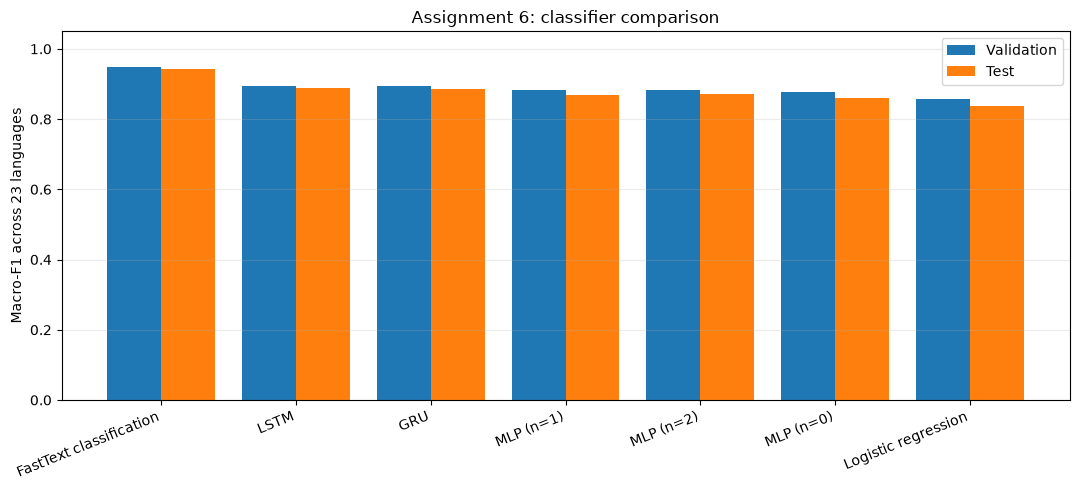

In [16]:
results_df = pd.DataFrame(result_rows).sort_values("Validation_Macro_F1", ascending=False).reset_index(drop=True)
expected_models = {"Logistic regression", "MLP (n=0)", "MLP (n=1)", "MLP (n=2)",
                   "LSTM", "GRU", "FastText classification"}
assert len(results_df) == 7 and set(results_df["Model"]) == expected_models
assert np.isfinite(results_df[["Validation_Macro_F1", "Test_Macro_F1"]].to_numpy()).all()
assert results_df[["Validation_Macro_F1", "Test_Macro_F1"]].ge(0).all().all()
assert results_df[["Validation_Macro_F1", "Test_Macro_F1"]].le(1).all().all()
results_df.to_csv(OUTPUT_DIR / "assignment6_classifier_comparison.csv", index=False)
display(results_df[["Model", "Validation_Macro_F1", "Test_Macro_F1", "Best_Epoch", "Training_Seconds"]].round(4))

fig, ax = plt.subplots(figsize=(11, 5))
positions = np.arange(len(results_df))
ax.bar(positions - 0.2, results_df["Validation_Macro_F1"], width=0.4, label="Validation")
ax.bar(positions + 0.2, results_df["Test_Macro_F1"], width=0.4, label="Test")
ax.set_xticks(positions, results_df["Model"], rotation=22, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Macro-F1 across 23 languages")
ax.set_title("Assignment 6: classifier comparison")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "macro_f1_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Training curves and error analysis

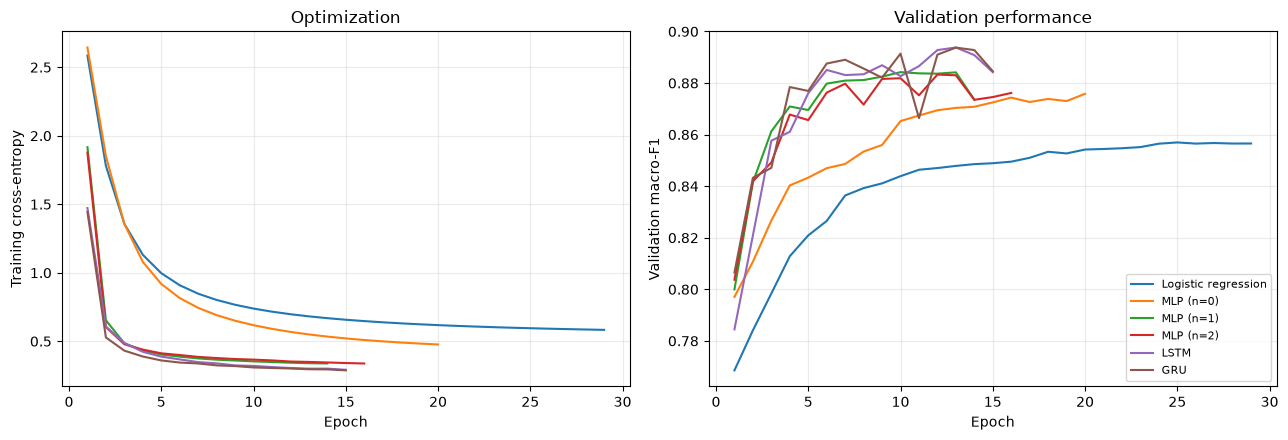

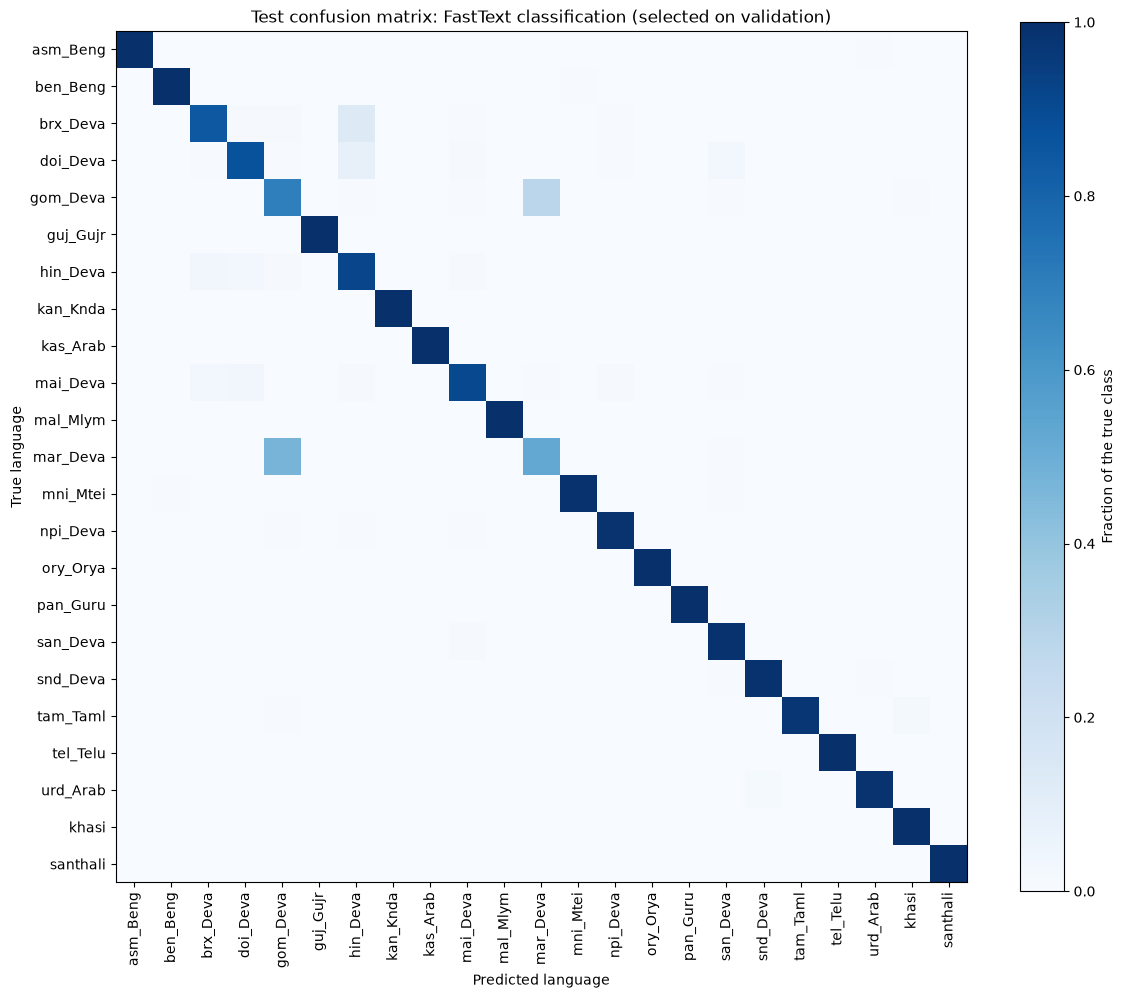

,language,test_f1,wiki_token_coverage,own_wiki_model_available
11,mar_Deva,0.5785,0.8322,True
4,gom_Deva,0.6318,0.7998,True
6,hin_Deva,0.8551,0.9229,True
2,brx_Deva,0.8825,0.3292,False
3,doi_Deva,0.8946,0.6164,False
9,mai_Deva,0.9282,0.7076,True
16,san_Deva,0.9706,0.4537,True
13,npi_Deva,0.9825,0.8393,True
18,tam_Taml,0.9873,0.7995,True
20,urd_Arab,0.9875,0.9266,True


Misclassified test examples:


,sentence_id,sentence,true_language,predicted_language,correct
43,43,(ফটো : AFP),asm_Beng,urd_Arab,False
297,297,হা হা হা,ben_Beng,mni_Mtei,False
408,408,"हालांकि, चीनी सैनिकों के विपरीत, भारतीय सैनिको...",brx_Deva,hin_Deva,False
427,427,“सरकार पूर्व मुख्य सचिव पीपी वर्मा की अध्यक्षत...,brx_Deva,hin_Deva,False
428,428,"इसके गठन के दिन से छह महीने का कार्यकाल होगा, ...",brx_Deva,hin_Deva,False
443,443,तेरी जैसी ही दुनिया अपनी,brx_Deva,doi_Deva,False
457,457,"रणनीतिक रूप से लाभप्रद स्थान के कारण, HDC ने ए...",brx_Deva,hin_Deva,False
471,471,"सेना के सूत्रों के मुताबिक, चीन ने ही सुबह 7:3...",brx_Deva,hin_Deva,False
472,472,इसके बाद से मेजर जनरल लेवल की बातचीत चल रही है,brx_Deva,hin_Deva,False
477,477,यह उन लोगों के लिए अच्छा दिन है जो स्व-रोज़गार...,brx_Deva,hin_Deva,False


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, records in histories.items():
    frame = pd.DataFrame(records)
    frame.to_csv(OUTPUT_DIR / f"{model_slug(name)}_training_history.csv", index=False)
    axes[0].plot(frame["epoch"], frame["train_loss"], label=name)
    axes[1].plot(frame["epoch"], frame["validation_macro_f1"], label=name)
axes[0].set_ylabel("Training cross-entropy")
axes[1].set_ylabel("Validation macro-F1")
axes[0].set_title("Optimization")
axes[1].set_title("Validation performance")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.25)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(PLOT_DIR / "training_curves.png", dpi=180, bbox_inches="tight")
plt.show()

best_model_name = results_df.loc[0, "Model"]
best_metrics = custom_classification_metrics(test_labels, saved_predictions[best_model_name]["test"])
confusion = best_metrics["confusion"]
normalized_confusion = confusion / np.maximum(confusion.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(12, 10))
plot = ax.imshow(normalized_confusion, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), LANGUAGES, rotation=90)
ax.set_yticks(range(NUM_CLASSES), LANGUAGES)
ax.set_xlabel("Predicted language")
ax.set_ylabel("True language")
ax.set_title(f"Test confusion matrix: {best_model_name} (selected on validation)")
fig.colorbar(plot, ax=ax, label="Fraction of the true class")
fig.tight_layout()
fig.savefig(PLOT_DIR / "selected_model_confusion.png", dpi=180, bbox_inches="tight")
plt.show()

test_coverage = coverage_df[coverage_df["split"] == "test"].set_index("language").loc[LANGUAGES]
selected_per_class = pd.DataFrame({
    "language": LANGUAGES, "test_f1": best_metrics["f1"],
    "wiki_token_coverage": test_coverage["coverage"].to_numpy(),
    "own_wiki_model_available": [WIKI_CODES[label] is not None for label in LANGUAGES],
})
selected_per_class.to_csv(OUTPUT_DIR / "selected_model_per_class_analysis.csv", index=False)
display(selected_per_class.sort_values("test_f1").round(4))

best_prediction_frame = pd.read_csv(OUTPUT_DIR / f"{model_slug(best_model_name)}_test_predictions.csv")
print("Misclassified test examples:")
display(best_prediction_frame[~best_prediction_frame["correct"]].head(10))

## 12. Observations and saved report

The report below is generated from the completed experiment, including the
measured scores, dataset provenance, embedding availability, and exact-text
overlap audit. It is written to `assignment6_artifacts/assignment6_report.md`.

In [18]:
from IPython.display import Markdown

table_lines = ["| Classifier | Validation macro-F1 | Test macro-F1 |",
               "| --- | ---: | ---: |"]
for row in results_df.itertuples(index=False):
    table_lines.append(f"| {row.Model} | {row.Validation_Macro_F1:.4f} | {row.Test_Macro_F1:.4f} |")

selected = results_df.iloc[0]
test_token_coverage = (test_coverage["covered_tokens"].sum() / test_coverage["word_tokens"].sum())
overlap_validation = int(duplicate_audit["validation_sentences_also_in_train"].sum())
overlap_test = int(duplicate_audit["test_sentences_also_in_train"].sum())
report = f"""# Assignment 6 - Language Identification

Tanu Meena, U23AI076

The experiment compares all seven required classifiers on the 23-language
Assignment 1 dataset. It uses 36,800 training, 4,600 validation, and 4,600 test
sentences, with 1,600/200/200 examples per language. {data_manifest['source']}
The reconstructed source revision, split hashes, labels, and hyperparameters are
saved with the results. The original notebook used 2,000 sentences per language,
so those counts are preserved despite Assignment 1's PDF specifying 1,000.

{chr(10).join(table_lines)}

The model selected by validation macro-F1 is **{selected['Model']}**, with
validation macro-F1 **{selected['Validation_Macro_F1']:.4f}** and test macro-F1
**{selected['Test_Macro_F1']:.4f}**. Test scores were not used for checkpoint or
model selection. Macro-F1 is implemented from a 23-by-23 confusion matrix using
NumPy; no sklearn evaluation classes or functions are used.

Logistic regression and MLP with zero hidden layers have the same linear-softmax
form. Their separate scores reflect different optimizers and validation-selected
checkpoints. The deeper MLPs introduce nonlinear features. LSTM and GRU also use
word order, while supervised FastText learns word and character n-grams and can
learn representations for training words missing from the Wiki lookup.

All six NumPy/PyTorch classifiers use one label-independent Wiki vector table.
The same word always has the same input vector regardless of its sentence's true
language. FastText receives the merged training-word vectors as initialization.
The full Wiki vector files for 18 languages were scanned; no row limit was used.
Their monolingual spaces are unaligned, and the fixed averaging rule should be
interpreted as a classification feature construction.

The official Wiki release lacks models for Bodo, Dogri, Manipuri, Khasi, and
Santali. These classes remain in all training and evaluation splits. Overall
test token coverage is **{test_token_coverage:.2%}**; language-level coverage and
all-OOV sentence counts are saved in `embedding_coverage.csv`. Entirely uncovered
sentences cannot be distinguished by the averaged zero-vector features, which
limits the embedding-only classifiers. Recurrent inputs are capped at
{MAX_SEQ_LEN} words; truncation counts are also saved.

The unchanged Assignment 1 sampling procedure produces **{overlap_validation}**
validation sentences and **{overlap_test}** test sentences whose exact text also
appears in training. They are retained for consistency with that procedure; this
overlap can increase measured scores and should be considered when interpreting
generalization. The language-level counts are in `duplicate_audit.csv`.

Artifacts include the comparison CSV, per-class precision/recall/F1, confusion
matrices, predictions, training histories, model checkpoints, cached vectors,
dataset splits, and plots. Set `FORCE_RETRAIN = True` to repeat model training.
Cached checkpoints are accepted only when their data/vector/configuration
signature matches the current experiment.
"""
report_path = OUTPUT_DIR / "assignment6_report.md"
report_path.write_text(report, encoding="utf-8")
display(Markdown(report))
print("Report:", report_path.resolve())

# Assignment 6 - Language Identification

Tanu Meena, U23AI076

The experiment compares all seven required classifiers on the 23-language
Assignment 1 dataset. It uses 36,800 training, 4,600 validation, and 4,600 test
sentences, with 1,600/200/200 examples per language. Reconstructed with Assignment 1's sampling and split procedure.
The reconstructed source revision, split hashes, labels, and hyperparameters are
saved with the results. The original notebook used 2,000 sentences per language,
so those counts are preserved despite Assignment 1's PDF specifying 1,000.

| Classifier | Validation macro-F1 | Test macro-F1 |
| --- | ---: | ---: |
| FastText classification | 0.9479 | 0.9417 |
| LSTM | 0.8938 | 0.8877 |
| GRU | 0.8937 | 0.8851 |
| MLP (n=1) | 0.8842 | 0.8696 |
| MLP (n=2) | 0.8833 | 0.8707 |
| MLP (n=0) | 0.8758 | 0.8606 |
| Logistic regression | 0.8570 | 0.8360 |

The model selected by validation macro-F1 is **FastText classification**, with
validation macro-F1 **0.9479** and test macro-F1
**0.9417**. Test scores were not used for checkpoint or
model selection. Macro-F1 is implemented from a 23-by-23 confusion matrix using
NumPy; no sklearn evaluation classes or functions are used.

Logistic regression and MLP with zero hidden layers have the same linear-softmax
form. Their separate scores reflect different optimizers and validation-selected
checkpoints. The deeper MLPs introduce nonlinear features. LSTM and GRU also use
word order, while supervised FastText learns word and character n-grams and can
learn representations for training words missing from the Wiki lookup.

All six NumPy/PyTorch classifiers use one label-independent Wiki vector table.
The same word always has the same input vector regardless of its sentence's true
language. FastText receives the merged training-word vectors as initialization.
The full Wiki vector files for 18 languages were scanned; no row limit was used.
Their monolingual spaces are unaligned, and the fixed averaging rule should be
interpreted as a classification feature construction.

The official Wiki release lacks models for Bodo, Dogri, Manipuri, Khasi, and
Santali. These classes remain in all training and evaluation splits. Overall
test token coverage is **68.48%**; language-level coverage and
all-OOV sentence counts are saved in `embedding_coverage.csv`. Entirely uncovered
sentences cannot be distinguished by the averaged zero-vector features, which
limits the embedding-only classifiers. Recurrent inputs are capped at
96 words; truncation counts are also saved.

The unchanged Assignment 1 sampling procedure produces **155**
validation sentences and **110** test sentences whose exact text also
appears in training. They are retained for consistency with that procedure; this
overlap can increase measured scores and should be considered when interpreting
generalization. The language-level counts are in `duplicate_audit.csv`.

Artifacts include the comparison CSV, per-class precision/recall/F1, confusion
matrices, predictions, training histories, model checkpoints, cached vectors,
dataset splits, and plots. Set `FORCE_RETRAIN = True` to repeat model training.
Cached checkpoints are accepted only when their data/vector/configuration
signature matches the current experiment.


Report: C:\Users\Tanu Meena\OneDrive\Desktop\llm\lab6\assignment6_artifacts\assignment6_report.md


## Assignment 6 checklist

- [x] Assignment 1's 23 labels, tokenizer, sample counts, and 80:10:10 split
- [x] Official FastText Wiki vectors, with missing-language and coverage reporting
- [x] Custom logistic regression using averaged word vectors
- [x] MLP with 0, 1, and 2 hidden layers
- [x] LSTM and GRU using padded/packed word-vector sequences
- [x] Actual supervised FastText library, initialized with Wiki vectors
- [x] Custom macro-F1 over all 23 classes, without sklearn
- [x] Seven-model comparison, per-class metrics, predictions, plots, and report